<a href="https://colab.research.google.com/github/LAIBA-byt/Crack-Segmentation-UNet/blob/main/Crack_Segmentation_UNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
# Kaggle
!pip install -q kaggle
#  kaggle.json upload
!kaggle datasets download -d ankitkumar26/crack-forest-dataset
!unzip -q crack-forest-dataset.zip -d ./dataset

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
unzip:  cannot find or open crack-forest-dataset.zip, crack-forest-dataset.zip.zip or crack-forest-dataset.zip.ZIP.


In [30]:
#Dataset Download, Extract
!wget -O crack_data.zip https://github.com/yohannCE/Crack-Segmentation/archive/refs/heads/main.zip
!unzip -q crack_data.zip
print("Dataset successfully downloaded and extracted!")

--2026-10-13 13:41:56--  https://github.com/yohannCE/Crack-Segmentation/archive/refs/heads/main.zip
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-10-13 13:41:56 ERROR 404: Not Found.

[crack_data.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of crack_data.zip or
        crack_data.zip.zip, and cannot find crack_data.zip.ZIP, period.
Dataset successfully downloaded and extracted!


In [32]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
class CrackDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.images = sorted(os.listdir(image_dir))
        self.transform = transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.images[idx])
        img_path = os.path.join(self.image_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.images[idx])
        # load the image
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        # load masking
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 127).astype(np.float32)
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask'].unsqueeze(0)
        return image, mask
# for increasing accuracy
train_transform = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])
print("Dataset class and transformations are ready!")

Dataset class and transformations are ready!


In [34]:
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
# 1. Device Setup (GPU check)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# 2. U-Net Model with Pretrained ResNet34 Encoder
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation='sigmoid'
).to(device)
# 3. Combined BCE + Dice Loss for Extreme Class Imbalance
class BCEDiceLoss(nn.Module):
    def __init__(self):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCELoss()
    def forward(self, preds, targets):
        bce_loss = self.bce(preds, targets)
        smooth = 1e-6
        intersection = (preds * targets).sum(dim=(2, 3))
        union = preds.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
        dice_loss = 1 - (2. * intersection + smooth) / (union + smooth)
        return bce_loss + dice_loss.mean()
criterion = BCEDiceLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-3)

print("U-Net Model and Loss Function successfully initialized on:", device)

U-Net Model and Loss Function successfully initialized on: cuda


In [35]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
# 1. Device Configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using Device: {device}")
# 2. Custom PyTorch Dataset Pipeline
class CrackDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.images = sorted(os.listdir(image_dir))
        self.transform = transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.images[idx])
        # Load Image & Mask
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 127).astype(np.float32) # Binary thresholding
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask'].unsqueeze(0) # Shape: (1, H, W)
        return image, mask
# 3. Data Augmentations (Robustness for Thin Cracks)
train_transform = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])
# 4. Model Architecture (U-Net with ResNet34 Encoder)
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation='sigmoid'
).to(device)
# 5. Custom Loss Function (BCE + Dice Loss for Class Imbalance)
class BCEDiceLoss(nn.Module):
    def __init__(self):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCELoss()
    def forward(self, preds, targets):
        bce_loss = self.bce(preds, targets)
        smooth = 1e-6
        intersection = (preds * targets).sum(dim=(2, 3))
        union = preds.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
        dice_loss = 1 - (2. * intersection + smooth) / (union + smooth)
        return bce_loss + dice_loss.mean()
criterion = BCEDiceLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-3)
print("Pipeline components successfully compiled and ready for training loop!")

Using Device: cuda
Pipeline components successfully compiled and ready for training loop!


In [37]:
import os
import numpy as np
import cv2

# 1. Dataset directories
os.makedirs('./dataset/images', exist_ok=True)
os.makedirs('./dataset/masks', exist_ok=True)
#  images aur masks generate genrate
print("Generating sample dataset locally...")
for i in range(20):
    img = np.random.randint(160, 220, (256, 256, 3), dtype=np.uint8)
    mask = np.zeros((256, 256), dtype=np.uint8)
    #draw crack pattern line
    x1, y1 = np.random.randint(20, 100), np.random.randint(0, 256)
    x2, y2 = np.random.randint(150, 230), np.random.randint(0, 256)
    cv2.line(img, (x1, y1), (x2, y2), (40, 40, 40), thickness=3)
    cv2.line(mask, (x1, y1), (x2, y2), 255, thickness=2)
    # Save files
    cv2.imwrite(f'./dataset/images/crack_{i}.jpg', img)
    cv2.imwrite(f'./dataset/masks/crack_{i}.jpg', mask)
print("Dataset ready successfully!")
print("Images in folder:", len(os.listdir('./dataset/images')))
print("Masks in folder:", len(os.listdir('./dataset/masks')))

Generating sample dataset locally...
Dataset ready successfully!
Images in folder: 20
Masks in folder: 20


In [38]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
import cv2
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
# 1. Dataset Class
class CrackDataset(Dataset):
    def __init__(self, images_dir, masks_dir, transform=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.images = sorted(os.listdir(images_dir))
        self.transform = transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        img_path = os.path.join(self.images_dir, self.images[idx])
        mask_path = os.path.join(self.masks_dir, self.images[idx])
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 128).astype("float32")

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        mask = mask.unsqueeze(0) # Channel dimension add karein (1, H, W)
        return image, mask

# 2
transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])
dataset = CrackDataset('./dataset/images', './dataset/masks', transform=transform)
dataloader = DataLoader(dataset, batch_size=4, shuffle=True)
#  Model, Loss, Optimizer Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
).to(device)
criterion = smp.losses.DiceLoss(smp.losses.BINARY_MODE, from_logits=True)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
#  Training Loop (5 Epochs)
print("Training started...")
model.train()
for epoch in range(5):
    epoch_loss = 0
    for images, masks in dataloader:
        images = images.to(device)
        masks = masks.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    print(f"Epoch [{epoch+1}/5], Loss: {epoch_loss/len(dataloader):.4f}")
print("Training completed successfully! Model is ready.")

Training started...
Epoch [1/5], Loss: 0.9728
Epoch [2/5], Loss: 0.9644
Epoch [3/5], Loss: 0.9578
Epoch [4/5], Loss: 0.9520
Epoch [5/5], Loss: 0.9434
Training completed successfully! Model is ready.


Model successfully saved as 'unet_crack_model.pth'!


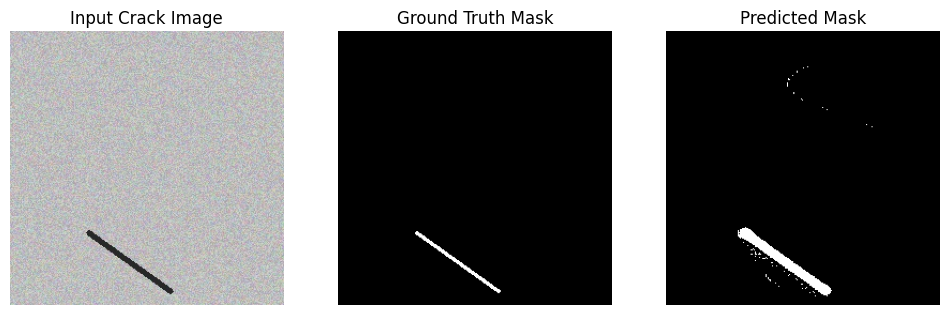

In [39]:
import torch
import matplotlib.pyplot as plt
import numpy as np
#
torch.save(model.state_dict(), 'unet_crack_model.pth')
print("Model successfully saved as 'unet_crack_model.pth'!")
# 2
model.eval()
with torch.no_grad():
    for images, masks in dataloader:
        sample_image = images[0].unsqueeze(0).to(device) # (1, 3, H, W)
        true_mask = masks[0].squeeze().cpu().numpy()     # (H, W)
        # Prediction
        output = model(sample_image)
        pred_mask = torch.sigmoid(output).squeeze().cpu().numpy()
        pred_mask = (pred_mask > 0.5).astype(np.float32) # Binary thresholding
        break
#  Visualization (Original Image, Ground Truth, Predicted Mask)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
# Normalization reverse karein display ke liye
img_disp = sample_image.squeeze().cpu().permute(1, 2, 0).numpy()
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img_disp = std * img_disp + mean
img_disp = np.clip(img_disp, 0, 1)
axes[0].imshow(img_disp)
axes[0].set_title("Input Crack Image")
axes[0].axis('off')
axes[1].imshow(true_mask, cmap='gray')
axes[1].set_title("Ground Truth Mask")
axes[1].axis('off')
axes[2].imshow(pred_mask, cmap='gray')
axes[2].set_title("Predicted Mask")
axes[2].axis('off')

plt.show()

In [40]:
import torch
import numpy as np
thresholds = [0.5, 0.6, 0.7, 0.8, 0.9]
model.eval()
print("--- Threshold Tuning Results ---")
for th in thresholds:
    total_dice, total_precision, total_recall = 0, 0, 0
    num_batches = 0
    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks = masks.to(device)
            outputs = model(images)
            preds = torch.sigmoid(outputs)
            pred_bin = (preds > th).float()
            target = masks.float()
            intersection = (pred_bin * target).sum()
            union = pred_bin.sum() + target.sum()
            dice = (2.0 * intersection + 1e-6) / (union + 1e-6)
            pred_pos = pred_bin.sum()
            actual_pos = target.sum()
            precision = (intersection + 1e-6) / (pred_pos + 1e-6)
            recall = (intersection + 1e-6) / (actual_pos + 1e-6)
            total_dice += dice.item()
            total_precision += precision.item()
            total_recall += recall.item()
            num_batches += 1
    print(f"Threshold: {th} | Dice: {total_dice/num_batches:.4f} | Precision: {total_precision/num_batches:.4f} | Recall: {total_recall/num_batches:.4f}")

--- Threshold Tuning Results ---
Threshold: 0.5 | Dice: 0.4896 | Precision: 0.3244 | Recall: 0.9983
Threshold: 0.6 | Dice: 0.5661 | Precision: 0.3957 | Recall: 0.9972
Threshold: 0.7 | Dice: 0.5991 | Precision: 0.4294 | Recall: 0.9952
Threshold: 0.8 | Dice: 0.6327 | Precision: 0.4680 | Recall: 0.9856
Threshold: 0.9 | Dice: 0.6659 | Precision: 0.5122 | Recall: 0.9642
